## Ejercicio 10

Trabajo Práctico — Reconstrucción y regularización en imágenes tomográficas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

from pathlib import Path
from tempfile import gettempdir
from urllib.request import urlopen
from zipfile import is_zipfile
from scipy.sparse import csr_matrix, issparse
from scipy.sparse.linalg import LinearOperator, eigsh

### Inciso a)

Usamos el archivo `datos_tomografia_final_128.npz` y la función de carga provistos en la
[carpeta del enunciado](https://drive.google.com/drive/folders/1HpzIhC8FguAjnscD0LctfESVCbHms8he?usp=sharing).
Copiamos las funciones de `cargar_datos_tomografia.py` en la celda siguiente para que este
notebook no dependa de otro archivo de código.

Si los datos están junto al notebook, se cargan desde ahí. En caso contrario, se descargan
una vez desde el enlace oficial y se guardan en una carpeta temporal. Esa primera descarga
requiere conexión a internet. `pathlib`, `tempfile`, `urllib` y `zipfile` forman parte de Python;
para el cálculo solamente usamos NumPy, SciPy y Matplotlib.

In [2]:
#!/usr/bin/env python3
"""Carga el dataset del ejercicio final de tomografia."""

from __future__ import annotations

from pathlib import Path

import numpy as np
from scipy.sparse import csr_matrix


def _cargar_csr(datos: np.lib.npyio.NpzFile, prefijo: str) -> csr_matrix:
    return csr_matrix(
        (
            datos[f"{prefijo}_data"],
            datos[f"{prefijo}_indices"],
            datos[f"{prefijo}_indptr"],
        ),
        shape=tuple(datos[f"{prefijo}_shape"]),
    )


def cargar_datos_tomografia(ruta: str | Path) -> dict:
    with np.load(ruta, allow_pickle=False) as datos:
        return {
            "A": _cargar_csr(datos, "A"),
            "b": datos["b"].copy(),
            "n": int(datos["n"]),
            "angulos": datos["angulos"].copy(),
            "posiciones_detector": datos["posiciones_detector"].copy(),
            "ruido_relativo": float(datos["ruido_relativo"]),
            "desviacion_ruido": float(datos["desviacion_ruido"]),
            "norma_ruido_esperada": float(datos["norma_ruido_esperada"]),
        }

In [3]:
nombre_archivo = "datos_tomografia_final_128.npz"
ruta_local = Path(nombre_archivo)
carpeta_temporal = Path(gettempdir()) / "tp_tomografia"
ruta_temporal = carpeta_temporal / nombre_archivo

if ruta_local.is_file():
    ruta_datos = ruta_local
else:
    carpeta_temporal.mkdir(exist_ok=True)
    if not ruta_temporal.is_file():
        url = "https://drive.google.com/uc?export=download&id=1zJW85V52pesFTXDXC1mZkIfeh0Udt79Z"
        with urlopen(url, timeout=120) as respuesta:
            contenido = respuesta.read()
        ruta_temporal.write_bytes(contenido)
    ruta_datos = ruta_temporal

if not is_zipfile(ruta_datos):
    raise ValueError("No se obtuvo un NPZ válido. Descargar los datos de la carpeta del enunciado "
                     "y colocarlos junto al notebook.")

datos = cargar_datos_tomografia(ruta_datos)
A = datos["A"].astype(np.float64)
b = datos["b"].astype(np.float64)
n = datos["n"]
angulos = datos["angulos"]
posiciones_detector = datos["posiciones_detector"]
norma_ruido_esperada = datos["norma_ruido_esperada"]
K = len(angulos)
q = len(posiciones_detector)

print("Resolución:", n)
print("Ángulos K:", K)
print("Detectores q:", q)
print("Dimensiones de A:", A.shape)
print("Dimensiones de b:", b.shape)
print("Entradas no nulas de A:", A.nnz)
print("Proporción de entradas no nulas:", A.nnz / (A.shape[0] * A.shape[1]))
print("Norma esperada del ruido:", norma_ruido_esperada)
assert issparse(A)
assert n == 128
assert A.shape == (K * q, n**2)
assert b.shape == (K * q,)

Resolución: 128
Ángulos K: 90
Detectores q: 183
Dimensiones de A: (16470, 16384)
Dimensiones de b: (16470,)
Entradas no nulas de A: 1876712
Proporción de entradas no nulas: 0.006954791144884639
Norma esperada del ruido: 75.96688842773438


Se obtienen $K=90$ ángulos y $q=183$ posiciones de detector. Por lo tanto,
$A\in\mathbb{R}^{16470\times16384}$ y $b\in\mathbb{R}^{16470}$.
La matriz tiene 1.876.712 entradas no nulas y se conserva en formato CSR.
Cada coeficiente mide una longitud de intersección, por lo que ya no es una matriz binaria.

### Inciso b)

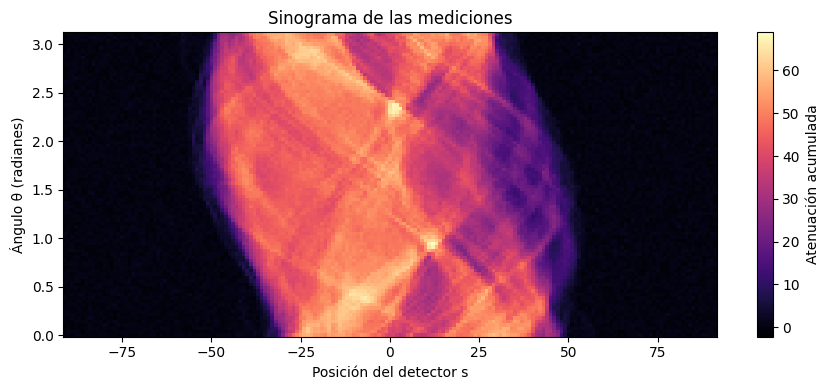

In [4]:
S = b.reshape(K, q)
assert np.array_equal(S.reshape(-1), b)
assert S.shape == (K, q)

fig, ax = plt.subplots(figsize=(9, 4))
im = ax.pcolormesh(posiciones_detector, angulos, S, shading="nearest", cmap="magma")
ax.set_xlabel("Posición del detector s")
ax.set_ylabel("Ángulo θ (radianes)")
ax.set_title("Sinograma de las mediciones")
fig.colorbar(im, ax=ax, label="Atenuación acumulada")
plt.tight_layout()
plt.show()

Cada fila de $S$ corresponde a un ángulo y cada columna a una posición del detector.
Usamos `reshape(K, q)` porque los datos están ordenados primero por ángulo y luego por
detector: $S_{kj}=b_{kq+j}$.

### Inciso c)

In [5]:
def matriz_diferencias(n):
    filas = []
    columnas = []
    valores = []
    r = 0

    # Primero agregamos las diferencias horizontales.
    for i in range(n):
        for j in range(n - 1):
            k = i * n + j
            filas.extend([r, r])
            columnas.extend([k, k + 1])
            valores.extend([-1.0, 1.0])
            r += 1

    # Después agregamos las diferencias verticales.
    for i in range(n - 1):
        for j in range(n):
            k = i * n + j
            filas.extend([r, r])
            columnas.extend([k, k + n])
            valores.extend([-1.0, 1.0])
            r += 1

    return csr_matrix((valores, (filas, columnas)), shape=(2 * n * (n - 1), n**2))

D = matriz_diferencias(n)
print("Dimensiones de D:", D.shape)
print("Entradas no nulas de D:", D.nnz)
print("No nulos por fila:", np.unique(D.getnnz(axis=1)))
assert D.shape == (32512, 16384)
assert np.all(D.getnnz(axis=1) == 2)
assert np.all(np.sort(D.data.reshape(-1, 2), axis=1) == [-1, 1])
assert np.allclose(D @ np.ones(n**2), 0)
prueba = np.arange(n**2, dtype=float).reshape(n, n)
assert np.allclose((D @ prueba.reshape(-1))[:n*(n-1)], np.diff(prueba, axis=1).reshape(-1))
assert np.allclose((D @ prueba.reshape(-1))[n*(n-1):], np.diff(prueba, axis=0).reshape(-1))

Dimensiones de D: (32512, 16384)
Entradas no nulas de D: 65024
No nulos por fila: [2]


### Inciso d)

Adaptamos gradiente descendiente para trabajar con productos entre matrices dispersas y
vectores. No construimos una matriz densa ni formamos $A^TA$. Guardamos las transpuestas
en CSR para reutilizarlas en las iteraciones.

Estimamos el mayor autovalor de $A^TA$ mediante un `LinearOperator` y `eigsh`, que solamente
necesitan el producto $v\mapsto A^T(Av)$. El resultado se usa para elegir una tasa estable.

In [6]:
AT = A.T.tocsr()
DT = D.T.tocsr()
operador_H = LinearOperator((n**2, n**2), matvec=lambda v: AT @ (A @ v), dtype=float)
mu_max = eigsh(operador_H, k=1, which="LA", return_eigenvectors=False,
               v0=np.ones(n**2), tol=1e-8)[0]

# Dejamos un pequeño margen sobre la estimación numérica.
L_A = 1.01 * mu_max
print("Mayor autovalor estimado de A.T @ A:", mu_max)
print("Cota utilizada para A.T @ A:", L_A)

Mayor autovalor estimado de A.T @ A: 11124.071666188347
Cota utilizada para A.T @ A: 11235.31238285023


Iteraciones sin regularización: 20000
Parada: máximo de iteraciones


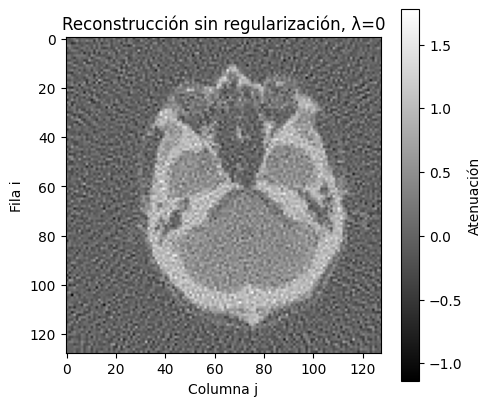

In [7]:
def gradiente_descendiente(A, b, D, lam, alpha, max_iter=20000, tol=1e-5):
    AT = A.T.tocsr()
    DT = D.T.tocsr()
    x = np.zeros(A.shape[1], dtype=float)
    norma_inicial = np.linalg.norm(AT @ b)
    costos = []
    normas_gradiente = []
    motivo = "máximo de iteraciones"

    for t in range(max_iter + 1):
        residuo = A @ x - b
        grad = AT @ residuo
        costo = 0.5 * np.dot(residuo, residuo)
        if lam != 0:
            diferencias = D @ x
            grad = grad + lam * (DT @ diferencias)
            costo += 0.5 * lam * np.dot(diferencias, diferencias)

        norma_grad = np.linalg.norm(grad)
        costos.append(float(costo))
        normas_gradiente.append(float(norma_grad))
        if not np.isfinite(costo):
            raise FloatingPointError("El costo dejó de ser finito; revisar la tasa.")
        if norma_grad <= tol * max(1.0, norma_inicial):
            motivo = "tolerancia del gradiente"
            break
        if t == max_iter:
            break
        x = x - alpha * grad

    return {"x": x, "alpha": alpha, "iteraciones": t, "motivo": motivo,
            "costos": np.array(costos), "normas_gradiente": np.array(normas_gradiente)}

# Para esta matriz de diferencias, lambda_max(D.T @ D) <= 8.
def tasa_estable(lam):
    return 1.8 / (L_A + 8.0 * lam)

resultados = {}
resultados[0.0] = gradiente_descendiente(A, b, D, 0.0, tasa_estable(0.0))
x_sin_reg = resultados[0.0]["x"]
print("Iteraciones sin regularización:", resultados[0.0]["iteraciones"])
print("Parada:", resultados[0.0]["motivo"])

fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(x_sin_reg.reshape(n, n), cmap="gray")
ax.set_title("Reconstrucción sin regularización, λ=0")
ax.set_xlabel("Columna j")
ax.set_ylabel("Fila i")
fig.colorbar(im, ax=ax, label="Atenuación", shrink=0.8)
plt.tight_layout()
plt.show()

La cota de ocho surge de que cada píxel tiene como máximo cuatro vecinos y cada diferencia
aporta a una matriz de tipo Laplaciano. Por lo tanto, usamos
$\alpha=1{,}8/(L_A+8\lambda)$, dentro del intervalo de estabilidad.

Detenemos las iteraciones cuando $\|\nabla J(x_t)\|\leq10^{-5}\max(1,\|\nabla J(x_0)\|)$
o al llegar a 20.000 pasos. Es una tolerancia de optimalidad, no un error de imagen.
La tabla informa el motivo de parada: si se alcanza el máximo, la reconstrucción es la
aproximación obtenida con ese presupuesto y no se afirma convergencia completa.

### Inciso e)

λ=0.1: 9942 iteraciones, tolerancia del gradiente
λ=1: 2423 iteraciones, tolerancia del gradiente
λ=10: 485 iteraciones, tolerancia del gradiente
λ=30: 254 iteraciones, tolerancia del gradiente
λ=100: 160 iteraciones, tolerancia del gradiente


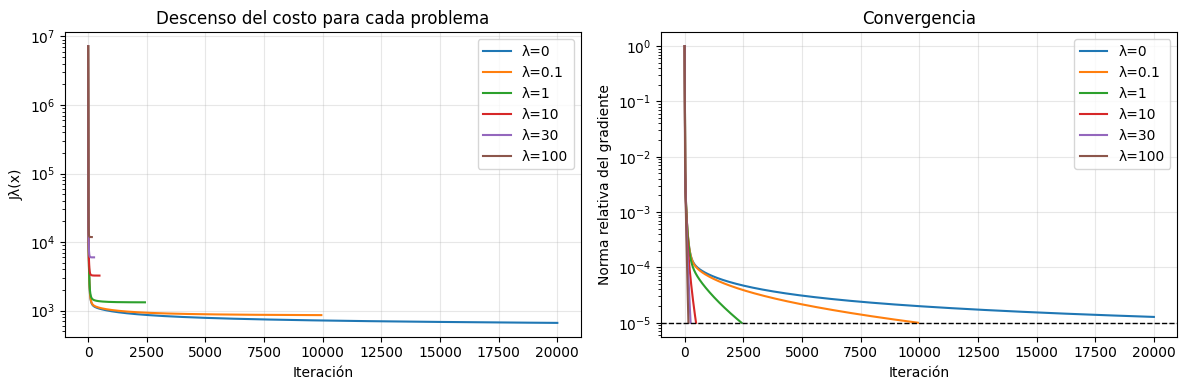

In [8]:
lambdas = [0.1, 1.0, 10.0, 30.0, 100.0]
for lam in lambdas:
    resultados[lam] = gradiente_descendiente(A, b, D, lam, tasa_estable(lam))
    print(f"λ={lam:g}: {resultados[lam]['iteraciones']} iteraciones, {resultados[lam]['motivo']}")

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for lam, resultado in resultados.items():
    axs[0].semilogy(resultado["costos"], label=f"λ={lam:g}")
    axs[1].semilogy(resultado["normas_gradiente"] / max(1.0, np.linalg.norm(AT @ b)),
                    label=f"λ={lam:g}")
    assert np.all(np.diff(resultado["costos"]) <= 1e-6)
axs[0].set_ylabel("Jλ(x)")
axs[0].set_title("Descenso del costo para cada problema")
axs[1].set_ylabel("Norma relativa del gradiente")
axs[1].set_title("Convergencia")
axs[1].axhline(1e-5, color="black", linestyle="--", linewidth=1)
for ax in axs:
    ax.set_xlabel("Iteración")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Cada curva de costo corresponde a una función distinta porque cambia λ. Su descenso permite
controlar la estabilidad de las iteraciones, pero comparar los costos finales entre λ distintos
no es un criterio para elegir la mejor reconstrucción.

### Inciso f)

     λ        Alpha   Iter.      Residuo    Variación     Mínimo     Máximo   Res./ruido
   0.0  1.60209e-04   20000      36.4003      68.6670    -1.1367     1.7763       0.4792
   0.1  1.60198e-04    9942      39.0586      44.1369    -0.6268     1.5017       0.5142
   1.0  1.60095e-04    2423      44.6622      25.4746    -0.2786     1.2073       0.5879
  10.0  1.59076e-04     485      55.4393      18.4836    -0.1505     1.1071       0.7298
  30.0  1.56858e-04     254      71.6056      15.1099    -0.1043     1.0761       0.9426
 100.0  1.49560e-04     160     102.7096      11.4617    -0.0626     1.0506       1.3520

Norma esperada del ruido: 75.96688842773438
λ=0: máximo de iteraciones
λ=0.1: tolerancia del gradiente
λ=1: tolerancia del gradiente
λ=10: tolerancia del gradiente
λ=30: tolerancia del gradiente
λ=100: tolerancia del gradiente


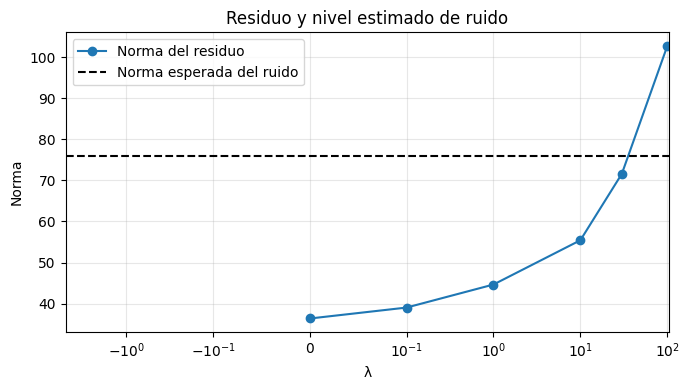

In [9]:
tabla = {}
print(f"{'λ':>6} {'Alpha':>12} {'Iter.':>7} {'Residuo':>12} {'Variación':>12} {'Mínimo':>10} {'Máximo':>10} {'Res./ruido':>12}")
for lam, resultado in resultados.items():
    x = resultado["x"]
    residuo = np.linalg.norm(A @ x - b)
    variacion = np.linalg.norm(D @ x)
    tabla[lam] = {"residuo": residuo, "variacion": variacion,
                  "minimo": x.min(), "maximo": x.max()}
    print(f"{lam:6.1f} {resultado['alpha']:12.5e} {resultado['iteraciones']:7d} "
          f"{residuo:12.4f} {variacion:12.4f} {x.min():10.4f} {x.max():10.4f} "
          f"{residuo / norma_ruido_esperada:12.4f}")

print("\nNorma esperada del ruido:", norma_ruido_esperada)
for lam, resultado in resultados.items():
    print(f"λ={lam:g}: {resultado['motivo']}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(tabla), [fila["residuo"] for fila in tabla.values()], "o-", label="Norma del residuo")
ax.axhline(norma_ruido_esperada, linestyle="--", color="black", label="Norma esperada del ruido")
ax.set_xscale("symlog", linthresh=0.1)
ax.set_xlabel("λ")
ax.set_ylabel("Norma")
ax.set_title("Residuo y nivel estimado de ruido")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Inciso g)

λ elegido: 30.0
Norma del residuo: 71.6056036450258
Norma de las diferencias: 15.10987623907257


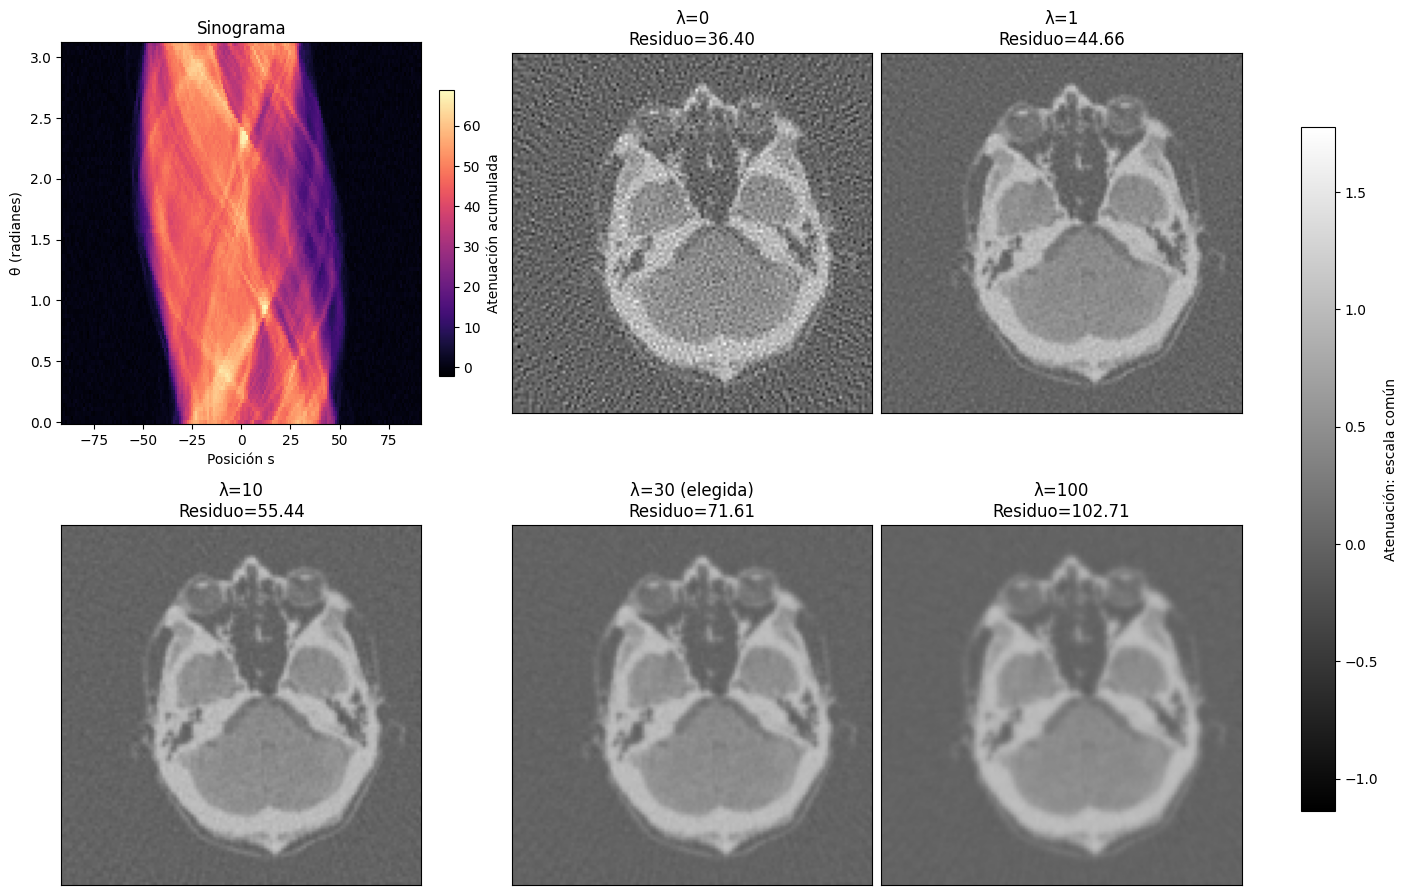

In [10]:
# Criterio de discrepancia: entre los valores probados elegimos un residuo cercano al ruido.
lambda_elegido = min(tabla, key=lambda lam: abs(tabla[lam]["residuo"] - norma_ruido_esperada))
print("λ elegido:", lambda_elegido)
print("Norma del residuo:", tabla[lambda_elegido]["residuo"])
print("Norma de las diferencias:", tabla[lambda_elegido]["variacion"])

mostrar = [0.0, 1.0, 10.0, 30.0, 100.0]
vmin = min(resultados[lam]["x"].min() for lam in mostrar)
vmax = max(resultados[lam]["x"].max() for lam in mostrar)
fig, axs = plt.subplots(2, 3, figsize=(14, 9), layout="constrained")
axs = axs.reshape(-1)
im_s = axs[0].pcolormesh(posiciones_detector, angulos, S, shading="nearest", cmap="magma")
axs[0].set_title("Sinograma")
axs[0].set_xlabel("Posición s")
axs[0].set_ylabel("θ (radianes)")
fig.colorbar(im_s, ax=axs[0], label="Atenuación acumulada", shrink=0.75)

for ax, lam in zip(axs[1:], mostrar):
    im = ax.imshow(resultados[lam]["x"].reshape(n, n), cmap="gray", vmin=vmin, vmax=vmax)
    marca = " (elegida)" if lam == lambda_elegido else ""
    ax.set_title(f"λ={lam:g}{marca}\nResiduo={tabla[lam]['residuo']:.2f}")
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(im, ax=list(axs[1:]), label="Atenuación: escala común", shrink=0.8)
plt.show()

Elegimos $\lambda=30$ entre los valores probados. Su residuo es aproximadamente $71{,}6$,
cercano a la norma esperada del ruido, $76{,}0$. Además, la imagen conserva las estructuras
principales y sus bordes, con menos oscilaciones que las reconstrucciones con $\lambda=0$
y $\lambda=1$.

La solución sin regularización ajusta más las mediciones, pero muestra variaciones pequeñas
e intensas en el fondo y dentro de las regiones. Un residuo mucho menor que el ruido sugiere
que también se está ajustando parte del ruido. Con $\lambda=10$ todavía se observa más textura
que con $\lambda=30$. Con $\lambda=100$, el residuo supera la estimación del ruido y los bordes
y detalles pequeños se ven más difusos.

La comparación usa una escala común para todas las reconstrucciones. El sinograma tiene
otra escala porque representa atenuaciones acumuladas, no valores de píxel.
No calculamos un error contra la imagen original porque esa imagen es desconocida.
El criterio de discrepancia y la inspección visual justifican la elección, pero no demuestran
que sea el mínimo error real ni que sea el mejor valor entre todos los $\lambda$ posibles.

Asistencia utilizada: ChatGPT / Codex para completar y revisar el código, las explicaciones y las verificaciones de este notebook.